In [2]:
# If using Google Colab, upload Sync_V1.xlsx when prompted.
from google.colab import files
uploaded = files.upload()  # choose Sync_V1.xlsx

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = next(name for name in uploaded if name.lower().endswith('.xlsx'))
raw = pd.read_excel(file_name, header=None)
raw.head(8)

Saving Sync_V1.xlsx to Sync_V1.xlsx


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,Stadium-facing cells: normal day vs last big m...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sites around the stadium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Site,Match phase,Time,Normal day: 4G anchor (B3) load %,Last match: 4G anchor (B3) load %,Normal day: 4G user speed Mbps,Last match: 4G user speed Mbps,Normal day: 5G user speed Mbps,Last match: 5G user speed Mbps,Last match: 5G connection success %,NaN,Site,Type,Distance from stadium centre (m),Backhaul,Backhaul capacity (Gbps),Has 5G (n78),NaN,NaN,NaN
2,M1,Crowd building up,17:00,20.6,58.6,15.6,7.5,153.14,129.25,99.2,NaN,M1,Macro,320,Fibre 10G,10,Yes,4G+5G,5G,8.0
3,M1,Innings break,21:00,21.1,98.8,15.3,1,148.69,32.51,35.2,NaN,M2,Macro,410,Fibre 10G,10,Yes,4G+5G,4G,14.0
4,M1,Final over,22:45,19.3,98.3,16.4,0.9,159.72,6.7,37,NaN,M3,Macro,290,Fibre 10G,10,Yes,4G+5G,NaN,NaN
5,M1,Post-match,23:15,20.4,98,15.7,0.9,148.58,46.68,37.8,NaN,M4,Macro,380,Microwave 2G,2,No,4G,NaN,NaN
6,M2,Crowd building up,17:00,21,63.1,16,7.6,145.37,132.82,99.2,NaN,M5,Macro,300,Fibre 10G,10,Yes,4G+5G,NaN,NaN
7,M2,Innings break,21:00,20.1,98.2,15.5,0.9,158.4,24.66,37.5,NaN,M6,Macro,450,Microwave 2G,2,No,4G,NaN,NaN


In [3]:
# The source workbook stores performance data in columns A:J, beginning on row 3.
headers = ['site','phase','time','normal_4g_load_pct','match_4g_load_pct',
           'normal_4g_speed_mbps','match_4g_speed_mbps','normal_5g_speed_mbps',
           'match_5g_speed_mbps','match_5g_connection_success_pct']
df = raw.iloc[2:34, 0:10].copy()
df.columns = headers
df = df[df['site'].isin(['M1','M2','M3','M4','M5','M6','S1','S2'])].copy()
df = df[df['phase'].isin(['Crowd building up','Innings break','Final over','Post-match'])]
for c in headers[3:]:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['site'] = df['site'].astype(str)
df.reset_index(drop=True, inplace=True)
print('Rows:', len(df), '| Sites:', df.site.nunique())
df.head(12)

Rows: 32 | Sites: 8


,site,phase,time,normal_4g_load_pct,match_4g_load_pct,normal_4g_speed_mbps,match_4g_speed_mbps,normal_5g_speed_mbps,match_5g_speed_mbps,match_5g_connection_success_pct
0,M1,Crowd building up,17:00,20.6,58.6,15.6,7.5,153.14,129.25,99.2
1,M1,Innings break,21:00,21.1,98.8,15.3,1.0,148.69,32.51,35.2
2,M1,Final over,22:45,19.3,98.3,16.4,0.9,159.72,6.70,37.0
3,M1,Post-match,23:15,20.4,98.0,15.7,0.9,148.58,46.68,37.8
4,M2,Crowd building up,17:00,21.0,63.1,16.0,7.6,145.37,132.82,99.2
5,M2,Innings break,21:00,20.1,98.2,15.5,0.9,158.40,24.66,37.5
6,M2,Final over,22:45,19.5,98.2,15.6,1.0,146.94,12.64,37.4
7,M2,Post-match,23:15,19.8,97.8,15.7,0.9,146.96,59.36,38.7
8,M3,Crowd building up,17:00,19.9,70.3,16.1,6.3,158.38,144.16,99.2
9,M3,Innings break,21:00,21.7,98.5,15.8,1.0,160.90,25.51,36.4


In [4]:
print('Missing values by column:')
display(df.isna().sum().to_frame('missing_count'))

# Flag impossible/contradictory records for investigation.
# M6 is listed as having no n78 5G in the site inventory, yet the KPI sheet reports 99.2% 5G connection success.
print('M6 records:')
display(df[df.site == 'M6'][['site','phase','match_4g_load_pct','match_5g_connection_success_pct']])

print('Sites with missing 5G speed data:')
display(df[df.match_5g_speed_mbps.isna()][['site','phase']].drop_duplicates())

Missing values by column:


,missing_count
site,0
phase,0
time,0
normal_4g_load_pct,0
match_4g_load_pct,0
normal_4g_speed_mbps,0
match_4g_speed_mbps,0
normal_5g_speed_mbps,16
match_5g_speed_mbps,16
match_5g_connection_success_pct,0


M6 records:


,site,phase,match_4g_load_pct,match_5g_connection_success_pct
20,M6,Crowd building up,25.3,99.2
21,M6,Innings break,60.5,99.2
22,M6,Final over,59.9,99.2
23,M6,Post-match,47.2,99.2


Sites with missing 5G speed data:


,site,phase
12,M4,Crowd building up
13,M4,Innings break
14,M4,Final over
15,M4,Post-match
20,M6,Crowd building up
21,M6,Innings break
22,M6,Final over
23,M6,Post-match
24,S1,Crowd building up
25,S1,Innings break


In [5]:
phase_order = ['Crowd building up','Innings break','Final over','Post-match']
summary = df.groupby('phase', sort=False).agg(
    avg_match_4g_load_pct=('match_4g_load_pct','mean'),
    avg_normal_4g_load_pct=('normal_4g_load_pct','mean'),
    avg_match_4g_speed_mbps=('match_4g_speed_mbps','mean'),
    avg_match_5g_speed_mbps=('match_5g_speed_mbps','mean'),
    avg_5g_connection_success_pct=('match_5g_connection_success_pct','mean')
).reindex(phase_order)
display(summary.round(2))

,avg_match_4g_load_pct,avg_normal_4g_load_pct,avg_match_4g_speed_mbps,avg_match_5g_speed_mbps,avg_5g_connection_success_pct
phase,,,,,
Crowd building up,64.34,20.95,7.94,138.80,98.78
Innings break,93.75,21.00,1.90,27.90,44.21
Final over,93.51,19.51,1.79,11.80,44.70
Post-match,92.01,19.51,2.06,49.74,44.39


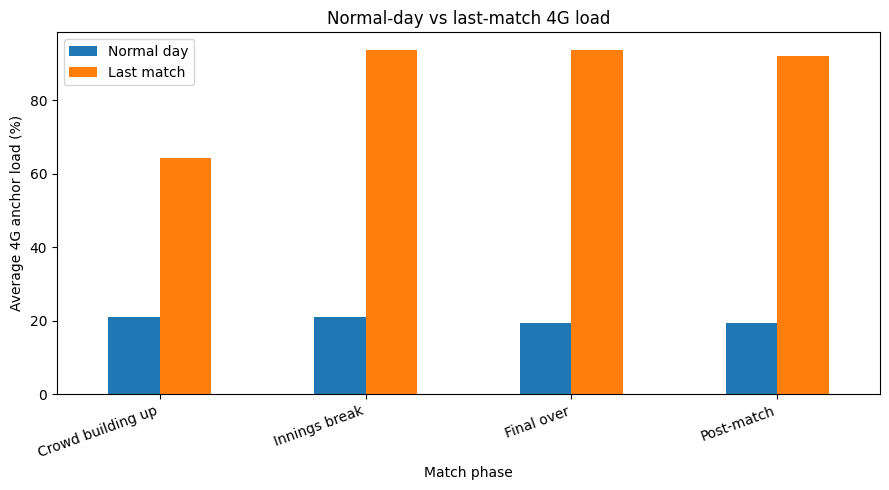

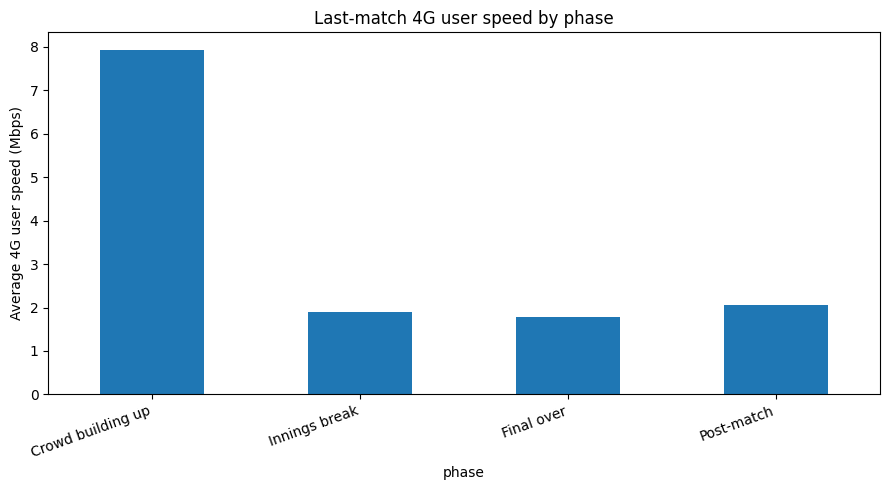

In [6]:
fig, ax = plt.subplots(figsize=(9,5))
summary[['avg_normal_4g_load_pct','avg_match_4g_load_pct']].plot(kind='bar', ax=ax)
ax.set_ylabel('Average 4G anchor load (%)'); ax.set_xlabel('Match phase')
ax.set_title('Normal-day vs last-match 4G load'); ax.legend(['Normal day','Last match'])
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,5))
summary[['avg_match_4g_speed_mbps']].plot(kind='bar', ax=ax, legend=False)
ax.set_ylabel('Average 4G user speed (Mbps)'); ax.set_title('Last-match 4G user speed by phase')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

In [7]:
fans = 100_000
airtel_share = 0.40
fiveg_share = 0.70
peak_online_share = 0.18
fiveg_target_mbps = 5
fourg_target_mbps = 3

airtel_users = fans * airtel_share
peak_active = airtel_users * peak_online_share
active_5g = peak_active * fiveg_share
active_4g = peak_active * (1-fiveg_share)
demand_5g_gbps = active_5g * fiveg_target_mbps / 1000
demand_4g_gbps = active_4g * fourg_target_mbps / 1000
print(f'Airtel users: {airtel_users:,.0f}')
print(f'Peak active users (18% of Airtel base): {peak_active:,.0f}')
print(f'Active 5G / 4G users: {active_5g:,.0f} / {active_4g:,.0f}')
print(f'5G demand: {demand_5g_gbps:.2f} Gbps')
print(f'4G demand: {demand_4g_gbps:.2f} Gbps')
print(f'Total offered throughput: {demand_5g_gbps+demand_4g_gbps:.2f} Gbps')


Airtel users: 40,000
Peak active users (18% of Airtel base): 7,200
Active 5G / 4G users: 5,040 / 2,160
5G demand: 25.20 Gbps
4G demand: 6.48 Gbps
Total offered throughput: 31.68 Gbps


In [8]:
# Site-wise average match-day 4G load

site_analysis = df.groupby('site').agg(
    avg_4g_load=('match_4g_load_pct', 'mean'),
    peak_4g_load=('match_4g_load_pct', 'max'),
    avg_4g_speed=('match_4g_speed_mbps', 'mean')
).reset_index()

site_analysis = site_analysis.sort_values(
    by='avg_4g_load',
    ascending=False
)

display(site_analysis.round(2))

,site,avg_4g_load,peak_4g_load,avg_4g_speed
7,S2,94.00,98.9,2.35
6,S1,93.80,98.3,2.25
4,M5,91.95,98.7,2.28
2,M3,91.40,98.5,2.30
3,M4,90.10,99.1,2.70
1,M2,89.32,98.2,2.60
0,M1,88.42,98.8,2.58
5,M6,48.22,60.5,10.32


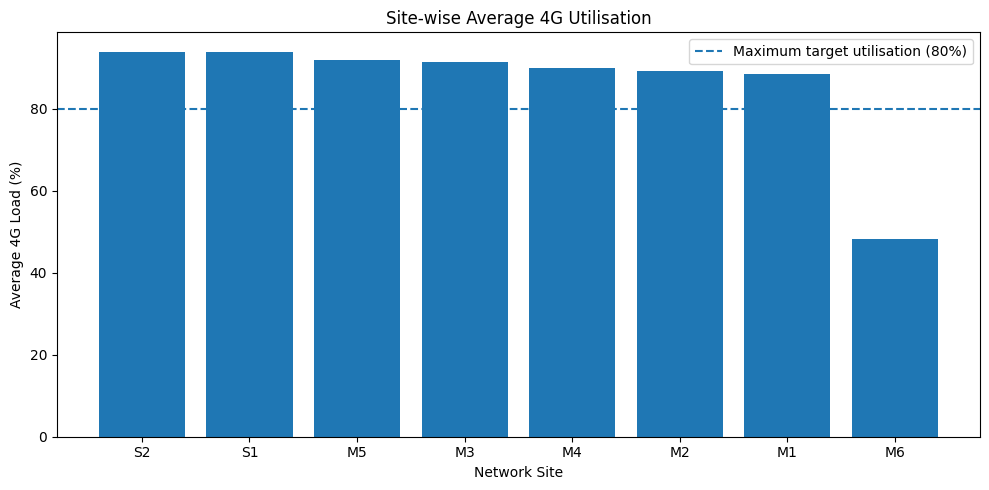

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    site_analysis['site'],
    site_analysis['avg_4g_load']
)

plt.axhline(
    y=80,
    linestyle='--',
    label='Maximum target utilisation (80%)'
)

plt.xlabel('Network Site')
plt.ylabel('Average 4G Load (%)')
plt.title('Site-wise Average 4G Utilisation')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Create a site-wise congestion matrix

load_matrix = df.pivot(
    index='site',
    columns='phase',
    values='match_4g_load_pct'
)

# Arrange phases in chronological order

phase_order = [
    'Crowd building up',
    'Innings break',
    'Final over',
    'Post-match'
]

load_matrix = load_matrix[phase_order]

display(load_matrix.round(2))

phase,Crowd building up,Innings break,Final over,Post-match
site,,,,
M1,58.6,98.8,98.3,98.0
M2,63.1,98.2,98.2,97.8
M3,70.3,98.5,98.3,98.5
M4,64.0,98.9,98.4,99.1
M5,72.4,98.7,98.4,98.3
M6,25.3,60.5,59.9,47.2
S1,80.6,98.3,98.0,98.3
S2,80.4,98.1,98.6,98.9


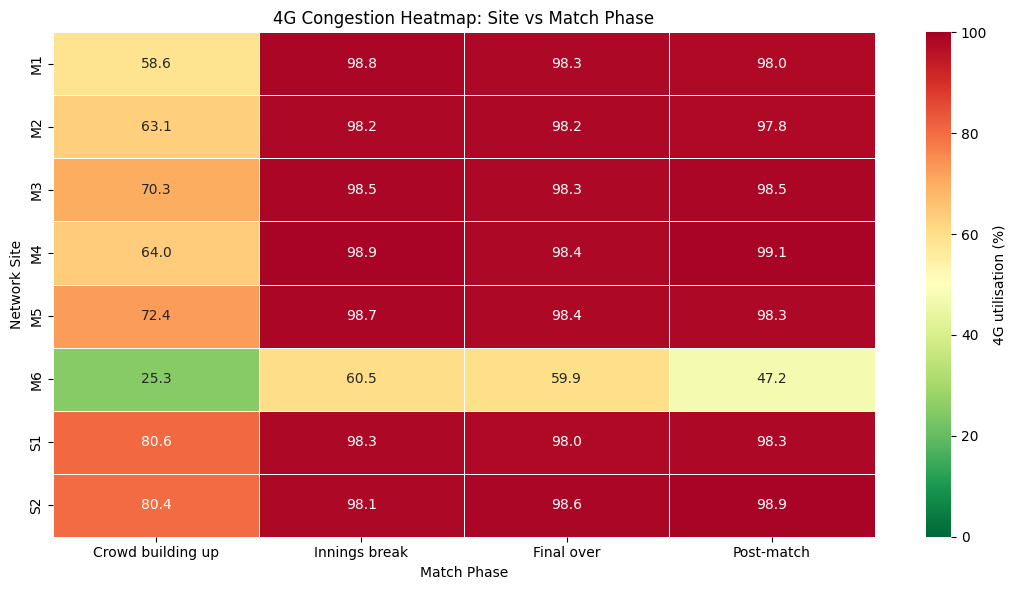

In [13]:
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.heatmap(
    load_matrix,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn_r',
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={'label': '4G utilisation (%)'}
)

plt.title('4G Congestion Heatmap: Site vs Match Phase')
plt.xlabel('Match Phase')
plt.ylabel('Network Site')

plt.tight_layout()
plt.show()

In [14]:
# Retain only sites with available 5G speed measurements

df_5g = df.dropna(
    subset=['match_5g_speed_mbps']
).copy()

# Calculate average 5G speed by match phase

fiveg_speed_analysis = df_5g.groupby('phase').agg(
    normal_5g_speed=('normal_5g_speed_mbps', 'mean'),
    match_5g_speed=('match_5g_speed_mbps', 'mean')
).reset_index()

fiveg_speed_analysis['speed_degradation_pct'] = (
    (fiveg_speed_analysis['normal_5g_speed'] -
     fiveg_speed_analysis['match_5g_speed']) /
    fiveg_speed_analysis['normal_5g_speed']
) * 100

display(fiveg_speed_analysis.round(2))

,phase,normal_5g_speed,match_5g_speed,speed_degradation_pct
0,Crowd building up,152.94,138.80,9.25
1,Final over,152.85,11.80,92.28
2,Innings break,155.04,27.90,82.00
3,Post-match,152.13,49.74,67.30


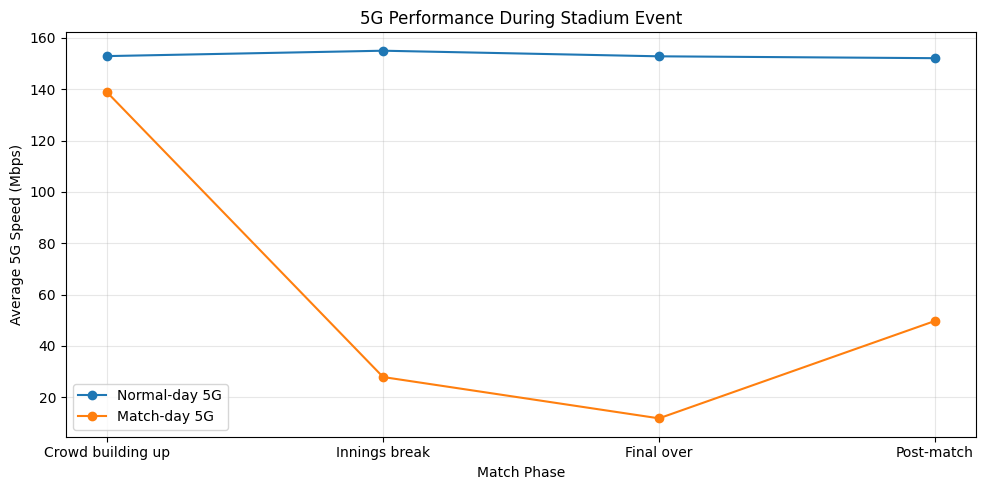

In [17]:
# Explicit chronological ordering

phase_order = [
    'Crowd building up',
    'Innings break',
    'Final over',
    'Post-match'
]

fiveg_speed_analysis['phase'] = pd.Categorical(
    fiveg_speed_analysis['phase'],
    categories=phase_order,
    ordered=True
)

fiveg_speed_analysis = fiveg_speed_analysis.sort_values(
    'phase'
)

plt.figure(figsize=(10, 5))

plt.plot(
    fiveg_speed_analysis['phase'],
    fiveg_speed_analysis['normal_5g_speed'],
    marker='o',
    label='Normal-day 5G'
)

plt.plot(
    fiveg_speed_analysis['phase'],
    fiveg_speed_analysis['match_5g_speed'],
    marker='o',
    label='Match-day 5G'
)

plt.ylabel('Average 5G Speed (Mbps)')
plt.xlabel('Match Phase')
plt.title('5G Performance During Stadium Event')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Site-wise 5G performance analysis

site_5g_analysis = df_5g.groupby('site').agg(
    normal_speed=('normal_5g_speed_mbps', 'mean'),
    match_speed=('match_5g_speed_mbps', 'mean'),
    avg_connection_success=(
        'match_5g_connection_success_pct', 'mean'
    )
).reset_index()

site_5g_analysis['speed_degradation_pct'] = (
    (site_5g_analysis['normal_speed'] -
     site_5g_analysis['match_speed']) /
    site_5g_analysis['normal_speed']
) * 100

display(site_5g_analysis.round(2))

,site,normal_speed,match_speed,avg_connection_success,speed_degradation_pct
0,M1,152.53,53.78,52.30,64.74
1,M2,149.42,57.37,53.20,61.60
2,M3,156.99,54.18,52.18,65.49
3,M5,154.02,62.90,52.18,59.16


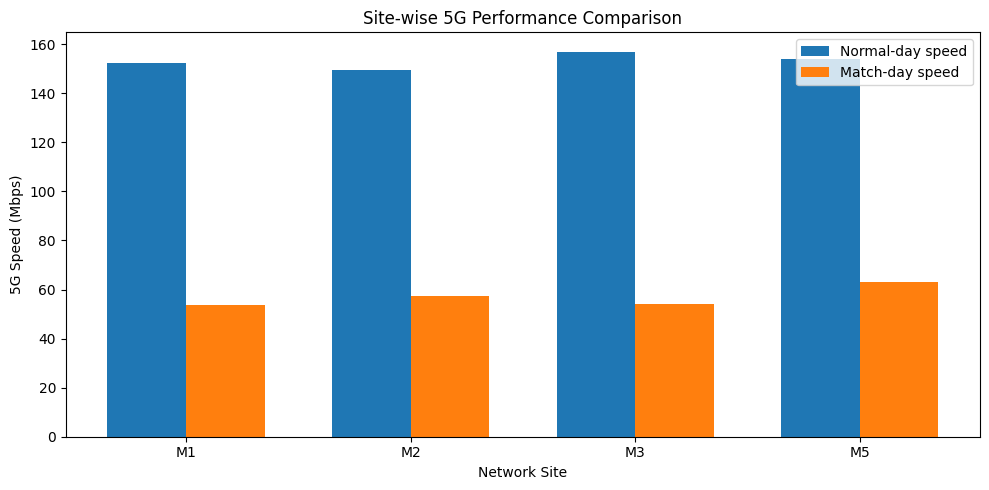

In [19]:
plt.figure(figsize=(10, 5))

x = np.arange(len(site_5g_analysis))
width = 0.35

plt.bar(
    x - width/2,
    site_5g_analysis['normal_speed'],
    width,
    label='Normal-day speed'
)

plt.bar(
    x + width/2,
    site_5g_analysis['match_speed'],
    width,
    label='Match-day speed'
)

plt.xticks(x, site_5g_analysis['site'])
plt.ylabel('5G Speed (Mbps)')
plt.xlabel('Network Site')
plt.title('Site-wise 5G Performance Comparison')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Analyse connection success at sites with 5G speed measurements

fiveg_connection = df[
    df['site'].isin(['M1', 'M2', 'M3', 'M5'])
].groupby('phase').agg(
    avg_connection_success=(
        'match_5g_connection_success_pct', 'mean'
    )
).reset_index()

display(fiveg_connection.round(2))

,phase,avg_connection_success
0,Crowd building up,99.20
1,Final over,37.02
2,Innings break,36.22
3,Post-match,37.40


In [20]:
# 5G speed matrix: site versus match phase

fiveg_matrix = df_5g.pivot(
    index='site',
    columns='phase',
    values='match_5g_speed_mbps'
)

phase_order = [
    'Crowd building up',
    'Innings break',
    'Final over',
    'Post-match'
]

fiveg_matrix = fiveg_matrix[phase_order]

display(fiveg_matrix.round(2))

phase,Crowd building up,Innings break,Final over,Post-match
site,,,,
M1,129.25,32.51,6.70,46.68
M2,132.82,24.66,12.64,59.36
M3,144.16,25.51,4.34,42.72
M5,148.96,28.92,23.54,50.20


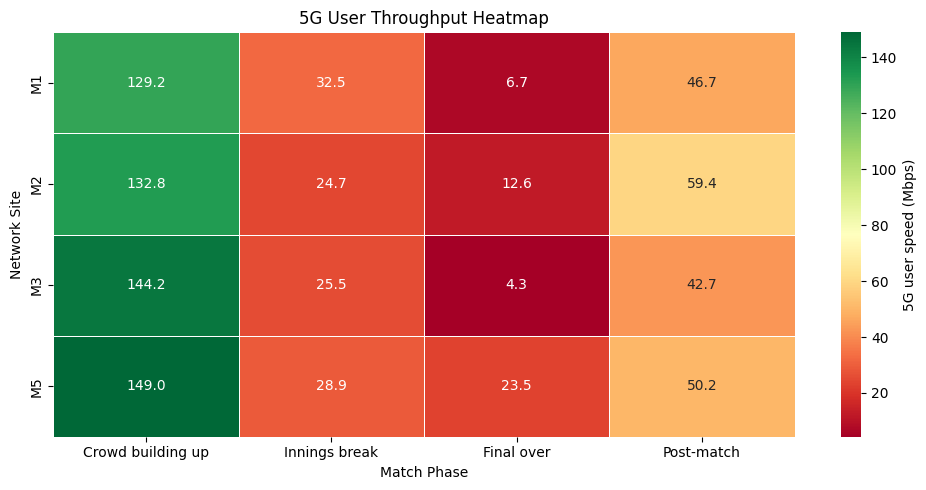

In [21]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.heatmap(
    fiveg_matrix,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    linewidths=0.5,
    cbar_kws={'label': '5G user speed (Mbps)'}
)

plt.title('5G User Throughput Heatmap')
plt.xlabel('Match Phase')
plt.ylabel('Network Site')

plt.tight_layout()
plt.show()

In [22]:
# Network capacity planning parameters

network_parameters = {
    'total_fans': 100000,
    'airtel_market_share': 0.40,
    'peak_active_user_percentage': 0.18,
    'fiveg_device_share': 0.70,

    'fiveg_user_target_mbps': 5,
    'fourg_user_target_mbps': 3,

    'maximum_cell_utilisation': 0.80,

    'total_4g_spectrum_mhz': 70,
    'total_5g_spectrum_mhz': 100
}

for parameter, value in network_parameters.items():
    print(f'{parameter}: {value}')

total_fans: 100000
airtel_market_share: 0.4
peak_active_user_percentage: 0.18
fiveg_device_share: 0.7
fiveg_user_target_mbps: 5
fourg_user_target_mbps: 3
maximum_cell_utilisation: 0.8
total_4g_spectrum_mhz: 70
total_5g_spectrum_mhz: 100


In [23]:
# Calculate demand under three traffic scenarios

scenarios = [0.15, 0.18, 0.25]

for activity in scenarios:

    active_users = (
        network_parameters['total_fans']
        * network_parameters['airtel_market_share']
        * activity
    )

    users_5g = active_users * 0.70
    users_4g = active_users * 0.30

    demand_5g = users_5g * 5 / 1000
    demand_4g = users_4g * 3 / 1000

    print(f'\nPeak activity: {activity*100:.0f}%')
    print(f'Active users: {active_users:.0f}')
    print(f'5G demand: {demand_5g:.2f} Gbps')
    print(f'4G demand: {demand_4g:.2f} Gbps')
    print(f'Total demand: {demand_5g+demand_4g:.2f} Gbps')


Peak activity: 15%
Active users: 6000
5G demand: 21.00 Gbps
4G demand: 5.40 Gbps
Total demand: 26.40 Gbps

Peak activity: 18%
Active users: 7200
5G demand: 25.20 Gbps
4G demand: 6.48 Gbps
Total demand: 31.68 Gbps

Peak activity: 25%
Active users: 10000
5G demand: 35.00 Gbps
4G demand: 9.00 Gbps
Total demand: 44.00 Gbps


In [24]:
import pandas as pd
import numpy as np

# Spectrum allocation
spectrum_5g = 100  # MHz
spectrum_4g = 70   # MHz

# Maximum permitted utilisation
max_utilisation = 0.80

# Spectral efficiency scenarios (bits/s/Hz)
efficiency_scenarios = {
    'Conservative': {'5G': 3, '4G': 1.5},
    'Base':         {'5G': 4, '4G': 2},
    'Optimistic':   {'5G': 6, '4G': 3}
}

# Traffic demand in Mbps
demand_5g = 25200
demand_4g = 6480

results = []

for scenario, efficiency in efficiency_scenarios.items():

    # Usable capacity per equivalent sector
    capacity_5g = (
        spectrum_5g * efficiency['5G']
        * max_utilisation
    )

    capacity_4g = (
        spectrum_4g * efficiency['4G']
        * max_utilisation
    )

    # Equivalent sector requirement
    sectors_5g = np.ceil(demand_5g / capacity_5g)
    sectors_4g = np.ceil(demand_4g / capacity_4g)

    results.append({
        'Scenario': scenario,
        '5G Capacity (Mbps)': capacity_5g,
        '4G Capacity (Mbps)': capacity_4g,
        '5G Sector Equivalents': int(sectors_5g),
        '4G Sector Equivalents': int(sectors_4g)
    })

capacity_results = pd.DataFrame(results)

display(capacity_results)

,Scenario,5G Capacity (Mbps),4G Capacity (Mbps),5G Sector Equivalents,4G Sector Equivalents
0,Conservative,240.0,84.0,105,78
1,Base,320.0,112.0,79,58
2,Optimistic,480.0,168.0,53,39


In [25]:
# Traffic activity scenarios
activity_scenarios = [0.15, 0.18, 0.25]

# Spectral efficiency scenarios
efficiency_scenarios = {
    'Conservative': {'5G': 3, '4G': 1.5},
    'Base': {'5G': 4, '4G': 2},
    'Optimistic': {'5G': 6, '4G': 3}
}

results = []

for activity in activity_scenarios:

    active_users = 100000 * 0.40 * activity

    users_5g = active_users * 0.70
    users_4g = active_users * 0.30

    demand_5g = users_5g * 5
    demand_4g = users_4g * 3

    for scenario, efficiency in efficiency_scenarios.items():

        capacity_5g = 100 * efficiency['5G'] * 0.80
        capacity_4g = 70 * efficiency['4G'] * 0.80

        sectors_5g = np.ceil(demand_5g / capacity_5g)
        sectors_4g = np.ceil(demand_4g / capacity_4g)

        results.append({
            'Activity': f'{activity*100:.0f}%',
            'Efficiency': scenario,
            '5G Demand (Mbps)': demand_5g,
            '4G Demand (Mbps)': demand_4g,
            '5G Sector Equivalents': int(sectors_5g),
            '4G Sector Equivalents': int(sectors_4g),
            'Total Sector Equivalents': int(sectors_5g + sectors_4g)
        })

sensitivity_df = pd.DataFrame(results)

display(sensitivity_df)

,Activity,Efficiency,5G Demand (Mbps),4G Demand (Mbps),5G Sector Equivalents,4G Sector Equivalents,Total Sector Equivalents
0,15%,Conservative,21000.0,5400.0,88,65,153
1,15%,Base,21000.0,5400.0,66,49,115
2,15%,Optimistic,21000.0,5400.0,44,33,77
3,18%,Conservative,25200.0,6480.0,105,78,183
4,18%,Base,25200.0,6480.0,79,58,137
5,18%,Optimistic,25200.0,6480.0,53,39,92
6,25%,Conservative,35000.0,9000.0,146,108,254
7,25%,Base,35000.0,9000.0,110,81,191
8,25%,Optimistic,35000.0,9000.0,73,54,127


In [26]:
# Extract infrastructure inventory from original workbook

infrastructure = raw.iloc[1:9, 11:17].copy()

infrastructure.columns = [
    'site',
    'site_type',
    'distance_m',
    'backhaul',
    'backhaul_capacity_gbps',
    'has_5g'
]

infrastructure.reset_index(drop=True, inplace=True)

display(infrastructure)

,site,site_type,distance_m,backhaul,backhaul_capacity_gbps,has_5g
0,Site,Type,Distance from stadium centre (m),Backhaul,Backhaul capacity (Gbps),Has 5G (n78)
1,M1,Macro,320,Fibre 10G,10,Yes
2,M2,Macro,410,Fibre 10G,10,Yes
3,M3,Macro,290,Fibre 10G,10,Yes
4,M4,Macro,380,Microwave 2G,2,No
5,M5,Macro,300,Fibre 10G,10,Yes
6,M6,Macro,450,Microwave 2G,2,No
7,S1,Small cell (in-bowl),80,Fibre 1G,1,No


In [28]:
# Extract the eight actual infrastructure records

infrastructure = raw.iloc[2:10, 11:17].copy()

infrastructure.columns = [
    'site',
    'site_type',
    'distance_m',
    'backhaul',
    'backhaul_capacity_gbps',
    'has_5g'
]

# Convert numerical columns
infrastructure['distance_m'] = pd.to_numeric(
    infrastructure['distance_m'],
    errors='coerce'
)

infrastructure['backhaul_capacity_gbps'] = pd.to_numeric(
    infrastructure['backhaul_capacity_gbps'],
    errors='coerce'
)

infrastructure.reset_index(drop=True, inplace=True)

display(infrastructure)

,site,site_type,distance_m,backhaul,backhaul_capacity_gbps,has_5g
0,M1,Macro,320,Fibre 10G,10,Yes
1,M2,Macro,410,Fibre 10G,10,Yes
2,M3,Macro,290,Fibre 10G,10,Yes
3,M4,Macro,380,Microwave 2G,2,No
4,M5,Macro,300,Fibre 10G,10,Yes
5,M6,Macro,450,Microwave 2G,2,No
6,S1,Small cell (in-bowl),80,Fibre 1G,1,No
7,S2,Small cell (in-bowl),80,Fibre 1G,1,No


In [29]:
print("Total sites:", len(infrastructure))

print("\nSite type distribution:")
display(infrastructure['site_type'].value_counts())

print("\n5G deployment status:")
display(infrastructure['has_5g'].value_counts())

print("\nBackhaul distribution:")
display(infrastructure['backhaul'].value_counts())

print("\nTotal nominal installed backhaul capacity:")

print(
    infrastructure['backhaul_capacity_gbps'].sum(),
    "Gbps"
)

Total sites: 8

Site type distribution:


,count
site_type,
Macro,6
Small cell (in-bowl),2



5G deployment status:


,count
has_5g,
Yes,4
No,4



Backhaul distribution:


,count
backhaul,
Fibre 10G,4
Microwave 2G,2
Fibre 1G,2



Total nominal installed backhaul capacity:
46 Gbps


Text(0, 0.5, '5G success %')

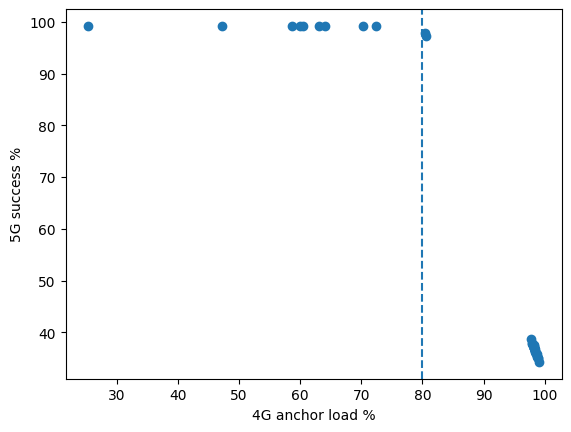

In [30]:
plt.scatter(df.match_4g_load_pct, df.match_5g_connection_success_pct)
plt.axvline(80, ls='--'); plt.xlabel('4G anchor load %'); plt.ylabel('5G success %')

In [31]:
# Merge performance and infrastructure datasets

site_scorecard = pd.merge(
    site_analysis,
    infrastructure,
    on='site',
    how='inner'
)

# Calculate how far each site exceeds the 80% target

site_scorecard['load_excess_pct'] = (
    site_scorecard['avg_4g_load'] - 80
).clip(lower=0)

# Identify preliminary intervention categories

def classify_site(row):

    if row['site_type'] == 'Small cell (in-bowl)':
        return 'In-bowl capacity expansion'

    elif row['has_5g'] == 'No':
        return '4G/5G and backhaul assessment'

    elif row['avg_4g_load'] >= 90:
        return 'Radio capacity optimisation'

    elif row['avg_4g_load'] >= 80:
        return 'Capacity optimisation'

    else:
        return 'Monitor / redistribution assessment'

site_scorecard['recommended_action'] = (
    site_scorecard.apply(classify_site, axis=1)
)

# Sort by average 4G congestion

site_scorecard = site_scorecard.sort_values(
    'avg_4g_load',
    ascending=False
)

display(site_scorecard.round(2))

,site,avg_4g_load,peak_4g_load,avg_4g_speed,site_type,distance_m,backhaul,backhaul_capacity_gbps,has_5g,load_excess_pct,recommended_action
0,S2,94.00,98.9,2.35,Small cell (in-bowl),80,Fibre 1G,1,No,14.00,In-bowl capacity expansion
1,S1,93.80,98.3,2.25,Small cell (in-bowl),80,Fibre 1G,1,No,13.80,In-bowl capacity expansion
2,M5,91.95,98.7,2.28,Macro,300,Fibre 10G,10,Yes,11.95,Radio capacity optimisation
3,M3,91.40,98.5,2.30,Macro,290,Fibre 10G,10,Yes,11.40,Radio capacity optimisation
4,M4,90.10,99.1,2.70,Macro,380,Microwave 2G,2,No,10.10,4G/5G and backhaul assessment
5,M2,89.32,98.2,2.60,Macro,410,Fibre 10G,10,Yes,9.33,Capacity optimisation
6,M1,88.42,98.8,2.58,Macro,320,Fibre 10G,10,Yes,8.42,Capacity optimisation
7,M6,48.22,60.5,10.32,Macro,450,Microwave 2G,2,No,0.00,4G/5G and backhaul assessment


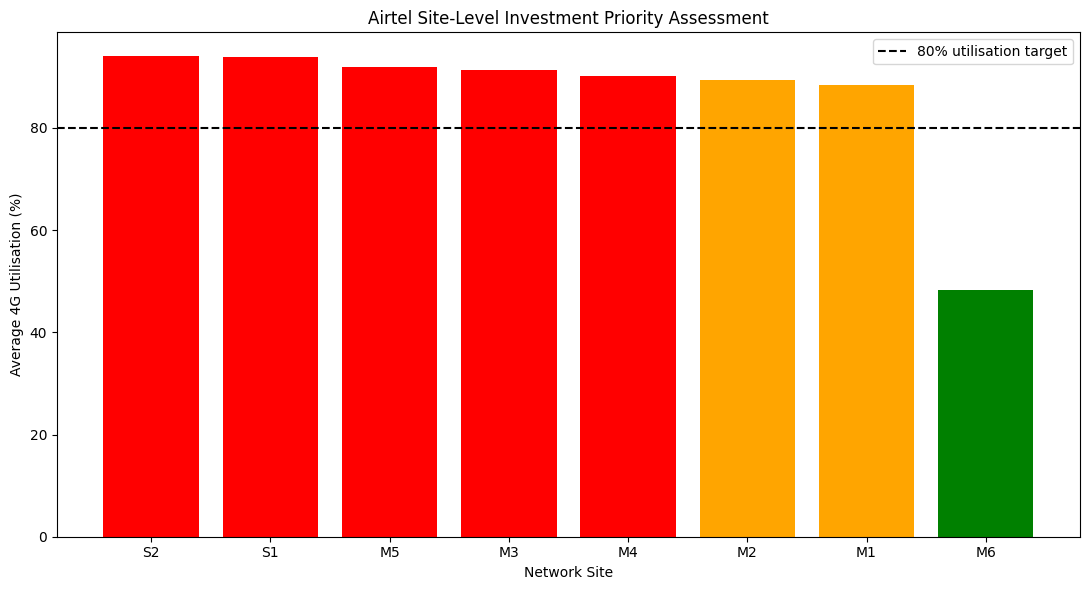

In [32]:
plt.figure(figsize=(11, 6))

colors = [
    'red' if x >= 90
    else 'orange' if x >= 80
    else 'green'
    for x in site_scorecard['avg_4g_load']
]

plt.bar(
    site_scorecard['site'],
    site_scorecard['avg_4g_load'],
    color=colors
)

plt.axhline(
    y=80,
    color='black',
    linestyle='--',
    label='80% utilisation target'
)

plt.xlabel('Network Site')
plt.ylabel('Average 4G Utilisation (%)')
plt.title('Airtel Site-Level Investment Priority Assessment')
plt.legend()

plt.tight_layout()
plt.show()